# AI-Assisted Decision-Support Framework for Disaster Relief Resource Allocation Under Uncertainty

This notebook reproduces the reported tables and figures from pinned experiment outputs. Run from the repository root or from the research directory. The technical guide provides commands for reconstructing original predictions, re-reading raster windows, rebuilding features and fitting new models. Historical obligations, physical observations, model estimates and simulated humanitarian need are separate data layers.

In [1]:
from pathlib import Path
from hashlib import sha256
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

study = Path("research") if Path("research/results").exists() else Path(".")
repo = study.resolve().parent
results = study / "results"
figures = study / "figures"
figures.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "savefig.bbox": "tight"})
blue, orange, green, slate = "#1f5a91", "#b35322", "#19705f", "#4c6170"

def load(name):
    return pd.read_csv(results / name)

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(figures / f"{name}.png", dpi=180)
    plt.show()
    plt.close(fig)

for entry in (study / "inputs/SHA256SUMS").read_text().splitlines():
    expected, relative = entry.split("  ", 1)
    assert sha256((repo / relative).read_bytes()).hexdigest() == expected, relative
print("Frozen workbook, retained archive and source-manifest hashes verified.")

Fontconfig error: No writable cache directories


Frozen workbook, retained archive and source-manifest hashes verified.


## 1. Frozen historical benchmark

The workbook contains 971 unique records from FY2010–24. The original historical target is nonnegative FEMA mission-assignment obligations in USD. Its six funding bands are left-closed at 0, 100,000, 1 million, 50 million, 200 million and 500 million. The frozen router used a leave-fiscal-year-out experiment that could use later years in training. Its target and protocol remain frozen.

In [2]:
cohort = load("hazards/cohort_features.csv")
frozen = load("track_a/all_912_immutable_overlay.csv")
assert len(cohort) == 971 and cohort.disasterNumber.is_unique
assert len(frozen) == 912 and frozen.actual_band.eq(frozen.router_pred).sum() == 830
amount = frozen.challenger_stack_prediction
assert np.isclose((amount-frozen.target).abs().mean(), 5014819.011614494)
display(load("track_a/model_metrics.csv").query("axis == 'all'")[
    ["variant","n","accuracy","balanced_accuracy","macro_f1","mae_usd","rmse_usd","r2"]].round(4))

,variant,n,accuracy,balanced_accuracy,macro_f1,mae_usd,rmse_usd,r2
0,track_a_original_stack,912,0.9101,0.8955,0.8786,5.131360e+06,6.471480e+07,0.8866
35,track_a_reported_historical_50_200m_overlay,912,0.9101,0.8955,0.8786,5.014819e+06,6.465375e+07,0.8868
70,track_a_two_accepted_low_specialists,912,0.9101,0.8955,0.8786,5.127644e+06,6.471478e+07,0.8866


## 2. Flood investigations and observability

Each window compares the preceding month with the incident-start month and the corresponding prior-year months. Only dry-to-water and water-to-dry transitions count. The common observation mask contains valid classifications on every required date. The minimum common threshold is 30% of window cells. Report gains and losses per 100 observable km² and subtract placebo net change from event net change. The annual placebo gives evidence about seasonality and cannot certify absence of flooding.

,threshold_percent,sites,disasters,event_gain_rate,event_loss_rate,placebo_gain_rate,placebo_loss_rate,delta_net_rate,median_case_delta
18,30,44,27,0.0809,0.1911,0.0278,0.0809,-0.0571,0.0
21,60,40,27,0.0835,0.1641,0.0287,0.0740,-0.0353,0.0
24,80,36,25,0.0872,0.1769,0.0309,0.0795,-0.0411,0.0


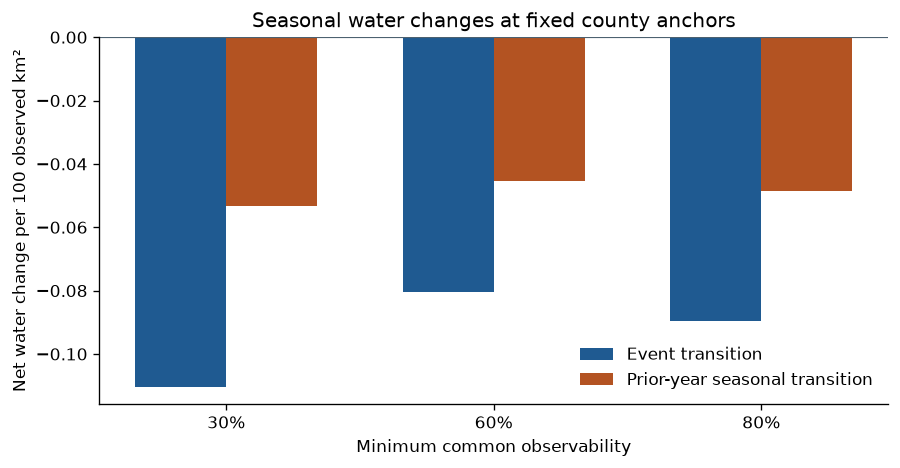

In [3]:
p50 = load("phase50/phase50_summary.csv")
replay = load("phase50/phase50_phase49_replay.csv")
months = load("phase50/phase50_monthly_source_log.csv")
assert replay.status.eq("exact_match").sum() == 67
assert months.status.eq("read_ok").sum() == 289
seasonal = p50.query("design == 'seasonal' and denominator == 'common' and population == 'anchors'")
display(seasonal[["threshold_percent","sites","disasters","event_gain_rate","event_loss_rate",
                  "placebo_gain_rate","placebo_loss_rate","delta_net_rate","median_case_delta"]].round(4))
fig, ax = plt.subplots(figsize=(7.6, 4))
x = np.arange(len(seasonal))
ax.bar(x-.17, seasonal.event_net_rate, width=.34, color=blue, label="Event transition")
ax.bar(x+.17, seasonal.placebo_net_rate, width=.34, color=orange, label="Prior-year seasonal transition")
ax.set(xticks=x, xticklabels=[f"{n}%" for n in seasonal.threshold_percent],
       xlabel="Minimum common observability", ylabel="Net water change per 100 observed km²",
       title="Seasonal water changes at fixed county anchors")
ax.axhline(0, color=slate, linewidth=.7)
ax.legend(frameon=False)
finish(fig, "phase50_seasonal_water")

### Independent evidence in Minnesota

The two Houston County windows with the strongest Landsat water gains had overlap with flood-colored cells in NASA's independent three-day MODIS rendering. The relatively coarse render and the incomplete coverage limit this to local overlap. Transparent cells have ambiguous dry and missing states. Record dates precede, span and follow the April 11 incident start. The USGS gauge series test regional hydrologic context only.

,date,sample_id,jrc_gain_centers,gaining_centers_with_tile,gaining_centers_in_rendered_flood_cell
0,2023-04-10,4722_27055_2,5407,5407,2473
1,2023-04-20,4722_27055_2,5407,5407,896
2,2023-04-25,4722_27055_2,5407,5407,462
3,2024-04-25,4722_27055_2,5407,5407,225
4,2023-04-10,4722_27055_3,2288,2288,1170
5,2023-04-20,4722_27055_3,2288,2288,1279
6,2023-04-25,4722_27055_3,2288,2288,25


,station_name,year,time,value,unit_of_measure
1,Mississippi River at Aitkin,2022,2022-04-30,8400,ft^3/s
3,Mississippi River at Aitkin,2023,2023-04-25,14100,ft^3/s
5,Mississippi River at Aitkin,2024,2024-04-30,4320,ft^3/s
7,Root River near Houston,2022,2022-04-14,4420,ft^3/s
9,Root River near Houston,2023,2023-04-02,4160,ft^3/s
11,Root River near Houston,2024,2024-04-20,940,ft^3/s


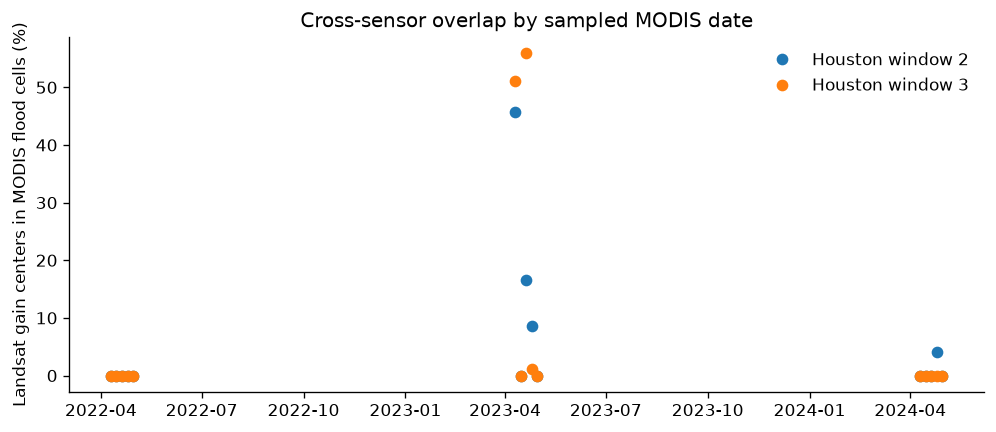

In [4]:
overlay = load("phase51/dr4722_modis_jrc_overlay.csv")
display(overlay.query("gaining_centers_in_rendered_flood_cell > 0").reset_index(drop=True))
gauge = load("phase51/dr4722_gauge_monthly_peaks.csv")
display(gauge.query("month == 4")[["station_name","year","time","value","unit_of_measure"]])
zoom = overlay[overlay.sample_id.isin(["4722_27055_2","4722_27055_3"])].copy()
zoom["overlap_fraction"] = zoom.gaining_centers_in_rendered_flood_cell / zoom.jrc_gain_centers
fig, ax = plt.subplots(figsize=(8.4, 3.7))
for name, group in zoom.groupby("sample_id"):
    ax.plot(pd.to_datetime(group.date), 100*group.overlap_fraction, "o", label=f"Houston window {name[-1]}")
ax.set(ylabel="Landsat gain centers in MODIS flood cells (%)",
       title="Cross-sensor overlap by sampled MODIS date")
ax.legend(frameon=False)
finish(fig, "dr4722_sensor_overlap")

## 3. Multi-hazard measurements and coverage

Make the county/date/event linkage explicit and retain the source identifiers. Hurricane estimates use track-date and location matching with post-event best tracks. MTBS named assignments require perimeter intersection. NOAA county records and ComCat links are candidate associations. NASA Daymet values are gridded estimates. The population column describes total designated-county population. Missing values remain missing until training-only preprocessing.

,incidentType,total,designated_2020_population,noaa_event_count,measured_gust_kt,tornado_ef,cyclone_max_wind_kt,mtbs_burned_acres,quake_magnitude,daymet_point_max_24h_mm
0,Severe Storm,430,369,301,123,155,0,0,0,0
1,Flood,198,167,157,0,0,0,0,0,87
2,Hurricane,108,83,67,0,0,86,0,0,0
3,Biological,59,44,0,0,0,0,0,0,0
4,Snowstorm,36,34,0,0,0,0,0,0,0
5,Fire,33,28,0,0,0,0,4,0,0
6,Tornado,27,25,25,0,25,0,0,0,0
7,Severe Ice Storm,21,21,0,0,0,0,0,0,0
8,Winter Storm,11,7,0,0,0,0,0,0,0
9,Mud/Landslide,9,4,1,0,0,0,0,0,0


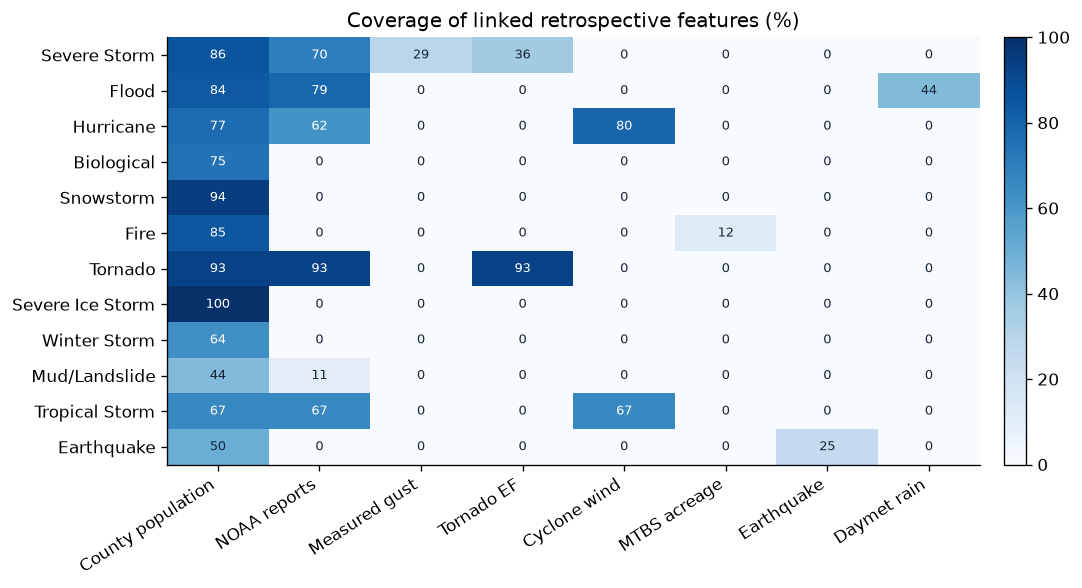

In [5]:
coverage = load("hazards/hazard_coverage.csv")
cols = ["designated_2020_population","noaa_event_count","measured_gust_kt","tornado_ef",
        "cyclone_max_wind_kt","mtbs_burned_acres","quake_magnitude","daymet_point_max_24h_mm"]
short = ["County population","NOAA reports","Measured gust","Tornado EF",
         "Cyclone wind","MTBS acreage","Earthquake","Daymet rain"]
show = coverage.query("total >= 8").sort_values("total", ascending=False).copy()
display(show[["incidentType","total",*cols]].reset_index(drop=True))
pct = show[cols].div(show.total, axis=0).to_numpy() * 100
fig, ax = plt.subplots(figsize=(9.8, 5))
im = ax.imshow(pct, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_yticks(np.arange(len(show)), show.incidentType)
ax.set_xticks(np.arange(len(short)), short, rotation=33, ha="right")
for i, row in enumerate(pct):
    for j, v in enumerate(row):
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v > 53 else "#172638", fontsize=8)
ax.set_title("Coverage of linked retrospective features (%)")
fig.colorbar(im, ax=ax, pad=.025)
finish(fig, "hazard_feature_coverage")

## 4. Forward validation and funding estimates

For each held year, take strictly earlier fiscal years and remove training events whose dates intersect the earliest held-out incident and groups shared with the test cases. Within the training data, select classifier hyperparameters by six-class macro F1 and amount hyperparameters by mean absolute dollar error on two earlier chronological origins. All variants score the same 376 cases. Historical calendar sources can be revised after the disaster.

,test_year,n_train,n_test,max_train_fy,max_train_end,min_test_incident_start,rejected_earlier_records,inner_years,linear_probability_weight,linear_amount_weight
0,2019,514,68,2018,2018-04-20,2018-05-01,22,"2017,2018",0.50,1
1,2020,593,43,2019,2019-06-25,2019-06-30,11,"2018,2019",0.25,1
2,2021,638,57,2020,2020-05-22,2020-06-29,9,"2019,2020",0.25,1
3,2022,692,52,2021,2021-07-10,2021-07-12,12,"2020,2021",0.25,0
4,2023,746,68,2022,2022-07-05,2022-07-12,10,"2021,2022",0.25,0
5,2024,796,88,2023,2023-04-30,2023-05-01,28,"2022,2023",0.00,0


,variant,accuracy,balanced_accuracy,macro_f1,mae_usd,r2
0,ablation_combined,0.59309,0.32088,0.27781,1.990280e+07,-0.01088
23,ablation_geography,0.57979,0.30150,0.26680,1.989300e+07,-0.01022
46,ablation_geography_physical,0.58245,0.33043,0.27750,1.990318e+07,-0.01093
69,ablation_metadata,0.46011,0.40749,0.22370,1.986446e+07,-0.00906
92,ablation_physical,0.48936,0.26502,0.22604,1.987878e+07,-0.01064
115,ablation_report_proxy,0.56117,0.29111,0.25435,1.992176e+07,-0.00933
138,ablation_retrospective_metadata,0.51064,0.42524,0.24315,1.989201e+07,-0.00986
161,ablation_verified_link_only,0.59574,0.33191,0.28435,1.990514e+07,-0.01088
184,equal_blend_verified,0.60106,0.30323,0.28061,3.128839e+07,-0.66691
207,hard_funding_band,0.59574,0.33191,0.28435,8.085428e+07,-3.83792


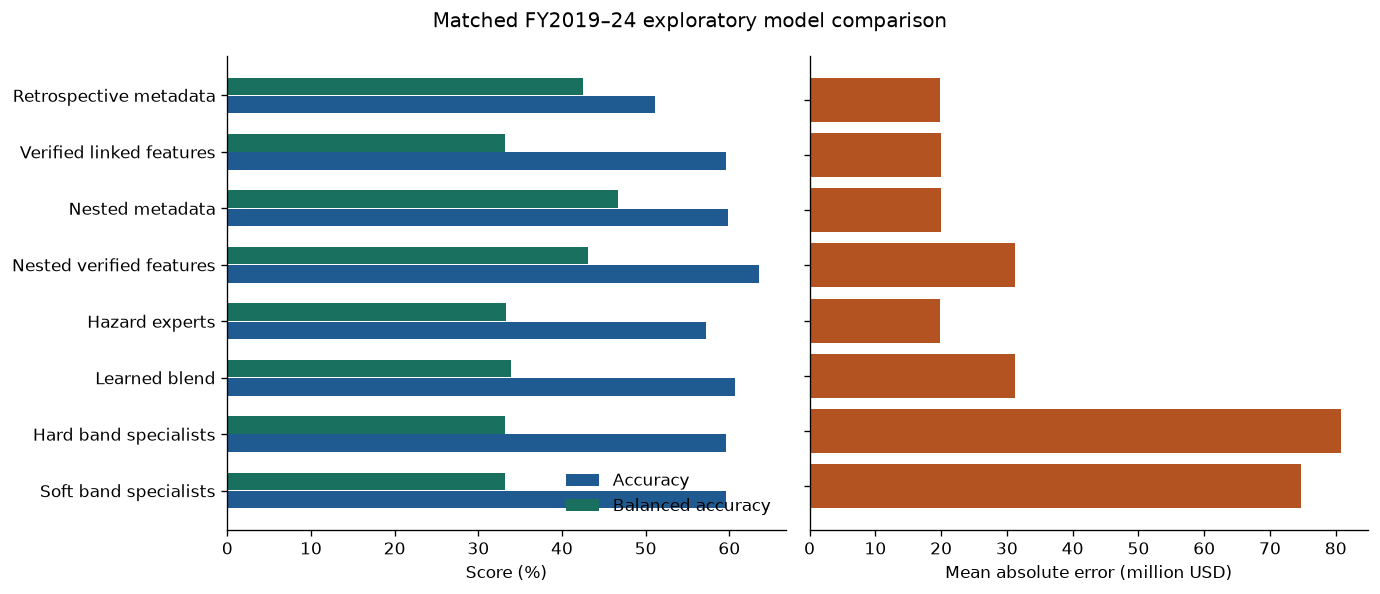

In [6]:
fold = load("forward/forward_fold_audit.csv")
p = load("forward/forward_predictions.csv")
assert (fold.max_train_fy < fold.test_year).all()
assert (pd.to_datetime(fold.max_train_end) < pd.to_datetime(fold.min_test_incident_start)).all()
assert p.groupby("variant").size().eq(376).all()
assert np.allclose(p[[f"p_band_{i}" for i in range(6)]].sum(axis=1), 1)
metrics = load("forward/model_metrics.csv").query("axis == 'all'").copy()
display(fold)
display(metrics[["variant","accuracy","balanced_accuracy","macro_f1","mae_usd","r2"]].round(5))
order = ["ablation_retrospective_metadata","ablation_verified_link_only","nested_metadata","nested_verified_link_only",
         "hazard_experts_verified","oof_weighted_blend_verified","hard_funding_band","soft_funding_band"]
labels = ["Retrospective metadata", "Verified linked features", "Nested metadata", "Nested verified features",
          "Hazard experts", "Learned blend", "Hard band specialists", "Soft band specialists"]
m = metrics.set_index("variant").loc[order]
fig, axs = plt.subplots(1, 2, figsize=(11.6, 5))
y = np.arange(len(order))
axs[0].barh(y+.16, 100*m.accuracy, height=.31, color=blue, label="Accuracy")
axs[0].barh(y-.16, 100*m.balanced_accuracy, height=.31, color=green, label="Balanced accuracy")
axs[0].set(yticks=y, yticklabels=labels, xlabel="Score (%)")
axs[0].invert_yaxis()
axs[0].legend(frameon=False)
axs[1].barh(y, m.mae_usd/1e6, color=orange)
axs[1].set(yticks=y, yticklabels=[], xlabel="Mean absolute error (million USD)")
axs[1].invert_yaxis()
fig.suptitle("Matched FY2019–24 exploratory model comparison")
finish(fig, "matched_forward_comparison")

### Grouped interpretation and a prospective cohort

The differences between fixed Extra Trees ablations quantify the incremental contribution of a feature family under this procedure. These changes cannot establish causal effects. The 143-case FY2025 roster was collected without outcome dollars. Authentic contemporaneous sources and mature comparable outcomes are required for a new independent test.

In [7]:
deltas = load("forward/paired_event_bootstrap.csv")
display(deltas[deltas.variant.str.startswith("ablation")][
    ["variant","accuracy_difference","accuracy_ci_low","accuracy_ci_high","mae_difference_usd","mae_ci_low","mae_ci_high"]].round(4))
new_ids = load("follow_up/fy2025_target_free_roster.csv")
assert len(new_ids) == 143 and not new_ids.disasterNumber.isin(cohort.disasterNumber).any()
display(new_ids.groupby("incidentType").size().sort_values(ascending=False).rename("reserved declarations").to_frame())

,variant,accuracy_difference,accuracy_ci_low,accuracy_ci_high,mae_difference_usd,mae_ci_low,mae_ci_high
0,ablation_combined,0.0824,0.0323,0.1362,10792.2458,-18704.7460,45393.6050
1,ablation_geography,0.0691,0.0277,0.1157,987.2165,-29193.0486,28411.6513
2,ablation_geography_physical,0.0718,0.0242,0.1206,11170.9042,-17752.8663,43135.8703
3,ablation_metadata,-0.0505,-0.0844,-0.0174,-27548.8205,-52010.9241,-6729.2407
4,ablation_physical,-0.0213,-0.0610,0.0191,-13232.3555,-63362.7405,22013.6101
5,ablation_report_proxy,0.0505,0.0026,0.0975,29752.5887,-22327.7875,94621.3749
6,ablation_retrospective_metadata,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
7,ablation_verified_link_only,0.0851,0.0384,0.1294,13131.1234,-14818.4044,45128.6843


,reserved declarations
incidentType,
Fire,82
Severe Storm,31
Flood,14
Tropical Storm,7
Hurricane,4
Winter Storm,2
Mud/Landslide,1
Severe Ice Storm,1
Tropical Depression,1


## 5. Prediction intervals and decline-to-automate decisions

The dollar and log1p methods calibrate residuals on earlier forward predictions. The conformal correction selects the order statistic at ceiling((n+1) × level), and the inverse transformation gives a USD interval. Chronological shift and very small upper bands limit coverage claims. A reviewer examines interval width, missing evidence, high band and low router probability separately.

,method,level,n,coverage,median_width_usd,mean_width_usd,review_rate
8,dollar,0.8,308,0.844156,7.485873e+05,8.663405e+05,0.516234
9,dollar,0.9,308,0.912338,4.283241e+06,4.004413e+06,0.516234
10,log1p,0.8,308,0.827922,1.598723e+05,2.471733e+09,0.542208
11,log1p,0.9,308,0.922078,8.980126e+05,1.200009e+10,0.574675


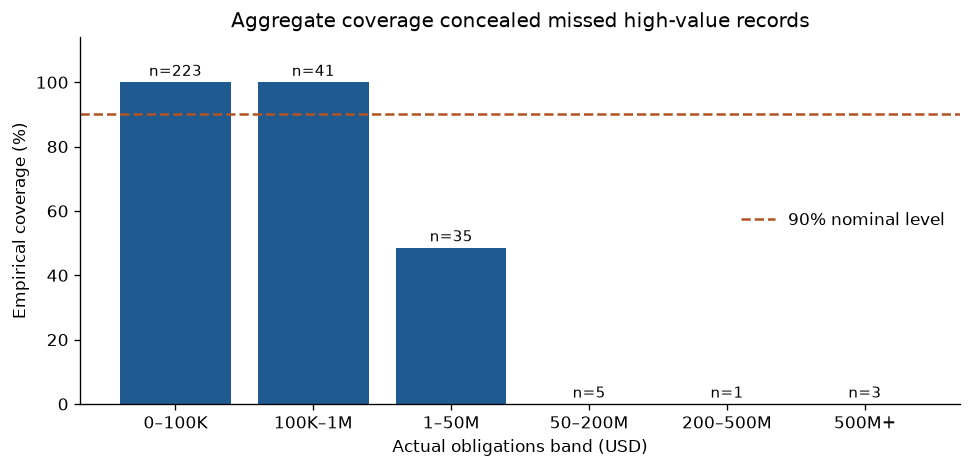

In [8]:
u = load("uncertainty/interval_metrics.csv")
main = u.query("variant == 'nested_metadata' and axis == 'all'")
display(main[["method","level","n","coverage","median_width_usd","mean_width_usd","review_rate"]])
bands = ["0–100K","100K–1M","1–50M","50–200M","200–500M","500M+"]
tail = u.query("variant == 'nested_metadata' and axis == 'actual_band' and method == 'dollar' and level == .9")
x = np.arange(len(bands))
fig, ax = plt.subplots(figsize=(8.2, 4))
ax.bar(x, 100*tail.coverage, color=blue)
for i, row in enumerate(tail.itertuples(index=False)):
    ax.text(i, 100*row.coverage+2, f"n={row.n}", ha="center", fontsize=9)
ax.axhline(90, linestyle="--", color=orange, label="90% nominal level")
ax.set(ylim=(0,114), xticks=x, xticklabels=bands, ylabel="Empirical coverage (%)",
       xlabel="Actual obligations band (USD)", title="Aggregate coverage concealed missed high-value records")
ax.legend(frameon=False, loc="center right")
finish(fig, "prediction_interval_coverage")

## 6. Allocation under uncertain need and budgets

The policy experiment uses independently simulated service needs across 12 events and three budget waves. Each scenario supplies the same arrivals, demand, and randomly released budgets to all seven candidate policies. Service is capped by realized need when scoring, while the policies depend only on the planning estimates available at an arrival wave. The illustrative result reports trade-offs in need served and service of higher-vulnerability groups.

,policy,need_met,p10_service_fraction,high_vulnerability_service,weighted_wait_units
42,efficient_expected,0.4969,0.1692,0.5272,10616.5230
43,equal,0.4543,0.2429,0.5089,11447.9446
44,equity_expected,0.4959,0.2332,0.6233,10391.9981
45,equity_robust,0.4883,0.1926,0.6522,10423.0841
46,exposure_priority,0.4075,0.0000,0.3667,12193.5762
47,proportional_need,0.4719,0.1617,0.4876,10993.0084
48,severity_priority,0.3991,0.0069,0.4129,12282.3263


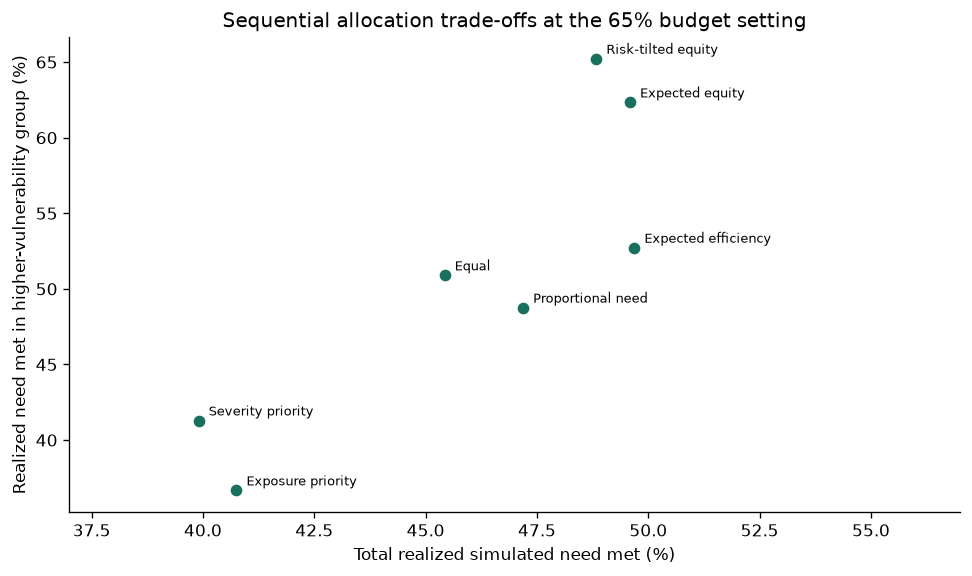

In [9]:
a = load("allocation/synthetic_allocation_metrics.csv")
focus = a.query("planned_budget_ratio == .65 and need_log_noise == .6 and arrival_type == 'sequential'")
display(focus[["policy","need_met","p10_service_fraction","high_vulnerability_service","weighted_wait_units"]].round(4))
fig, ax = plt.subplots(figsize=(8.2, 4.9))
policy_names = {"efficient_expected":"Expected efficiency", "equity_expected":"Expected equity",
                "equity_robust":"Risk-tilted equity", "equal":"Equal", "proportional_need":"Proportional need",
                "exposure_priority":"Exposure priority", "severity_priority":"Severity priority"}
for row in focus.itertuples(index=False):
    ax.scatter(100*row.need_met, 100*row.high_vulnerability_service, color=green)
    ax.annotate(policy_names[row.policy], (100*row.need_met,100*row.high_vulnerability_service),
                xytext=(6, 3), textcoords="offset points", fontsize=8)
ax.set(xlim=(37,57), xlabel="Total realized simulated need met (%)",
       ylabel="Realized need met in higher-vulnerability group (%)",
       title="Sequential allocation trade-offs at the 65% budget setting")
finish(fig, "allocation_tradeoffs")

## 7. Decision briefing

The historical disaster briefing shows observations, source availability, estimates, and review status. The policy section displays a different, synthetic event with estimated need, simulated outcomes and allocation in service units. See the technical guide for raw retrieval, full rebuilding and the command-line demonstration.

In [10]:
brief = json.loads((results/"decision_support_demonstration.json").read_text())
display(brief["historical_disaster"], brief["retrospective_model_estimate"])
display(pd.DataFrame(brief["simulated_humanitarian_allocation"]["policy_comparison"]))

{'id': 4722,
 'hazard': 'Flood',
 'state': 'MN',
 'recorded_dates': {'start': '2023-04-11', 'end': '2023-04-30'},
 'historical_fema_obligations_usd': 1243478.26,
 'evidence_fields_available': ['daymet_point_max_24h_mm',
  'daymet_point_incident_total_mm'],
 'evidence_fields_missing': ['measured_gust_kt',
  'estimated_gust_kt',
  'hail_in',
  'tornado_ef',
  'tornado_length_mi',
  'tornado_width_yd',
  'cyclone_max_wind_kt',
  'cyclone_min_pressure_mb',
  'cyclone_max_34kt_radius_nm',
  'cyclone_landfall_records',
  'mtbs_burned_acres',
  'quake_magnitude',
  'quake_depth_km',
  'quake_shakemap_max_mmi',
  'usgs_discharge_anomaly'],
 'evidence_provenance': 'research/SOURCE_AND_FEATURE_MANIFEST.csv'}

{'historical_obligation_estimate_usd': 5677.770840429999,
 'band': '1M-50M',
 'band_probabilities': {'0-100K': 0.0744928966533713,
  '100K-1M': 0.0027450918417107,
  '1M-50M': 0.9227620115049188,
  '50-200M': 0.0,
  '200-500M': 0.0,
  '500M+': 0.0},
 'intervals': [{'level': 0.8,
   'lower_usd': 0.0,
   'upper_usd': 754245.3430860257},
  {'level': 0.9, 'lower_usd': 0.0, 'upper_usd': 4288908.210935917}],
 'human_review': True,
 'availability_limit': 'later-year retrospective test, exact original decision-time versions unverified'}

,hazard,estimated_need_units,simulated_need_units,allocation_units,vulnerability,policy
0,winter,1090.424008,1144.62129,690.962514,0.437678,equal
1,winter,1090.424008,1144.62129,916.558737,0.437678,proportional_need
2,winter,1090.424008,1144.62129,1690.157213,0.437678,severity_priority
3,winter,1090.424008,1144.62129,0.000000,0.437678,exposure_priority
4,winter,1090.424008,1144.62129,867.428031,0.437678,efficient_expected
5,winter,1090.424008,1144.62129,708.775605,0.437678,equity_expected
6,winter,1090.424008,1144.62129,1090.424008,0.437678,equity_robust


## Conclusion and limitations

Preserve the historical model. The case study establishes uneven measurement coverage, localized cross-sensor flood agreement, and the difficulty of generalizing funding estimates across fiscal years and rare bands. The forward results and allocation simulation support research and human review. Further independent validation requires original decision-time source versions, mature outcome data, event-scale exposure verification and independent service-need labels.